# Mask quality at every step of the efish4-track pipeline

How good are the fish masks after each of the 10 pipeline steps (`segment` … `disturbance`)?

- **Loading**: every stage's masks come from `io_utils.load_stage_masks(run_dir, stage)` (step pickles `outputs/stages/NN_<stage>.pkl`, or `work/<stage>/masks.json` for runs still going).
- **Metrics**: computed in `mask_metrics.py`: `stage_quality` (per frame and fish, uses `frame_quality`, `crop_iou`, `solidity`, `hole_frac`, `centroid_shift`), `stage_checks` (my QC rules of `kaden_mask_qc.py` via `qc_checks`, plus the extra flags), `stage_summary` (% per stage and fish).
- **Plots**: the plot functions of `mask_stage_quality.py` (the same figures the script saves to `figures/mask_metrics/stages/<recording>/`).

Metrics per stage, frame and fish (visible masks):

| group | metric | good value |
|---|---|---|
| my QC rules | has a mask; area within 20% and length 0.8-1.2 x the fish's median; >= 99% in one piece; step <= 15 px and area change <= 15% to the previous and next frame; not within 5 px of another fish | pass |
| temporal | IoU with the fish's own mask in the previous frame, after moving it onto the current centroid (shape change without the swimming); flagged < 0.6 | high |
| identity | swap candidate: IoU with another fish's previous mask >= 0.3 and above the IoU with its own | rare |
| shape | solidity (area / convex hull; ~0.48 here because fins and chin are in the mask), holes, pieces | stable across steps |
| exclusivity | pixels shared with another fish's visible mask; visible mask inside the fish's own full-body mask | 0 / 1 |
| stage change | IoU with the same mask in the previous step and in the final step | - |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mask_metrics as mm                 # every quality metric
import mask_stage_quality as msq          # runs mm.stage_quality over the stages, and the plots
from io_utils import STAGES, load_stage_masks
%matplotlib inline
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

In [2]:
RUN = 'data/3_fish_silent/masks/video2024-10-15T15_30_54'   # one efish4-track run folder
RECOMPUTE = False                                               # True: recompute the per-frame metrics (~2 min), else use the cache
REC = RUN.rstrip('/').split('/')[-1]
FPS = msq.run_fps(RUN)

## Masks of every stage (`io_utils.load_stage_masks`)

In [3]:
stages = msq.stages_done(RUN)
masks = {st: load_stage_masks(RUN, st) for st in stages}
pd.DataFrame([dict(stage=mm.stage_label(st), fish=''.join(m.names), frames=len(m), size=m.shape,
                   masks=sum(len(m.encoded(k)) for k in range(len(m))))
              for st, m in masks.items()])

,stage,fish,frames,size,masks
0,1 segment,ABC,2615,"(912, 912)",7839
1,2 identity,ABC,2615,"(912, 912)",7839
2,3 contact,ABC,2615,"(912, 912)",7839
3,4 body masks,ABC,2615,"(912, 912)",7839
4,5 propagate,ABC,2615,"(912, 912)",7839
5,6 keypoints,ABC,2615,"(912, 912)",7836
6,7 extent,ABC,2615,"(912, 912)",7838
7,8 recover,ABC,2615,"(912, 912)",7838
8,9 ownership,ABC,2615,"(912, 912)",7841
9,10 disturbance,ABC,2615,"(912, 912)",7841


## Per-frame metrics (`mask_metrics.stage_quality`, `stage_checks`, `stage_summary`)

In [4]:
df, summary, checks, out = msq.load_or_compute(RUN, recompute=RECOMPUTE)
print(f'{len(df)} rows (stage x frame x fish); figures and tables in {out}')
df.head()

78450 rows (stage x frame x fish); figures and tables in figures/mask_metrics/stages/video2024-10-15T15_30_54


,stage,frame,fish,occluded,inferred,needs_review,confidence,cy,cx,major,minor,orient,n_comp,largest_frac,px,solidity,hole_frac,contact,overlap_px,area_amodal,...,present,step,darea,area_ratio,length_ratio,has a mask,area within 20% of median,length 0.8-1.2 x median,>= 99% in one piece,step <= 15 px,area change <= 15%,not touching other fish,all,all_but_contact,unstable,swap,overlap,outside_amodal,holes,changed
0,1 segment,0,A,False,False,False,1.0,109.370223,632.581016,278.999093,52.953862,13.371150,1.0,1.0,7301.0,0.512315,0.0,False,0.0,7301.0,...,True,3.393732,0.003150,1.029760,1.038441,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False
1,1 segment,0,B,False,False,False,1.0,187.292345,191.943200,242.925681,46.186114,126.396853,1.0,1.0,4912.0,0.589004,0.0,False,0.0,4912.0,...,True,13.227785,0.016897,1.038039,1.075257,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False
2,1 segment,0,C,False,False,False,1.0,207.783061,827.738114,202.495856,41.789518,90.996839,1.0,1.0,3849.0,0.430874,0.0,False,0.0,3849.0,...,True,2.441170,0.028579,0.992522,1.085785,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False
3,1 segment,1,A,False,False,False,1.0,108.114867,629.428002,277.269552,55.838804,11.990755,1.0,1.0,7278.0,0.482626,0.0,False,0.0,7278.0,...,True,3.393732,0.013190,1.026516,1.032004,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False
4,1 segment,1,B,False,False,False,1.0,197.547940,183.588735,236.659340,46.863278,123.208085,1.0,1.0,4829.0,0.570298,0.0,False,0.0,4829.0,...,True,13.227785,0.016897,1.020499,1.047521,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False


Pooled over fish: the headline numbers per stage (% of fish-frames).

In [5]:
cols = ['% pass all', '% pass all but touching', f'% aligned temporal IoU < {mm.IOU_LOW}', '% swap candidate',
        '% fail: >= 99% in one piece', '% with holes', '% overlap other fish', '% visible outside amodal',
        '% changed vs previous stage', 'median aligned temporal IoU', 'median solidity', 'mean IoU with final']
summary.groupby('stage', sort=False)[cols].mean().round(2)

,% pass all,% pass all but touching,% aligned temporal IoU < 0.6,% swap candidate,% fail: >= 99% in one piece,% with holes,% overlap other fish,% visible outside amodal,% changed vs previous stage,median aligned temporal IoU,median solidity,mean IoU with final
stage,,,,,,,,,,,,
1 segment,64.91,72.01,10.38,0.33,10.95,5.65,0.0,0.0,0.00,0.81,0.48,0.91
2 identity,64.91,72.01,10.38,0.33,10.95,5.65,0.0,0.0,0.00,0.81,0.48,0.91
3 contact,64.91,72.01,10.38,0.33,10.95,5.65,0.0,0.0,0.00,0.81,0.48,0.91
4 body masks,64.91,72.01,10.38,0.33,10.95,5.65,0.0,0.0,0.00,0.81,0.48,0.91
5 propagate,64.89,73.65,8.87,0.33,8.30,6.39,0.0,0.0,14.25,0.81,0.48,0.92
6 keypoints,65.06,74.72,10.21,0.43,6.39,3.95,0.0,0.0,21.47,0.81,0.49,0.95
7 extent,63.85,73.87,10.35,0.43,8.51,16.62,0.0,0.0,75.59,0.81,0.48,0.97
8 recover,63.85,73.87,10.34,0.43,8.49,16.60,0.0,0.0,0.13,0.81,0.48,0.97
9 ownership,64.00,75.65,6.54,0.13,7.71,19.07,0.0,0.0,23.47,0.81,0.49,1.00


## 1. My QC rules per step
% of fish-frames failing each rule, pooled over fish. *Touching* is about where the fish are, not the mask, so it is the same at every step; the last row leaves it out.

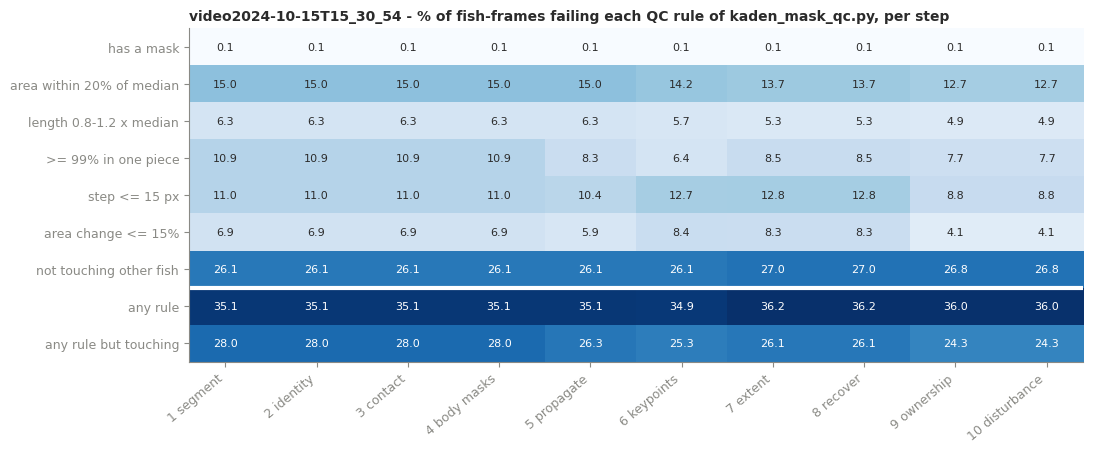

In [6]:
fig = msq.plot_qc_heatmap(summary, checks, REC)

## 2. Every metric per step, one line per fish

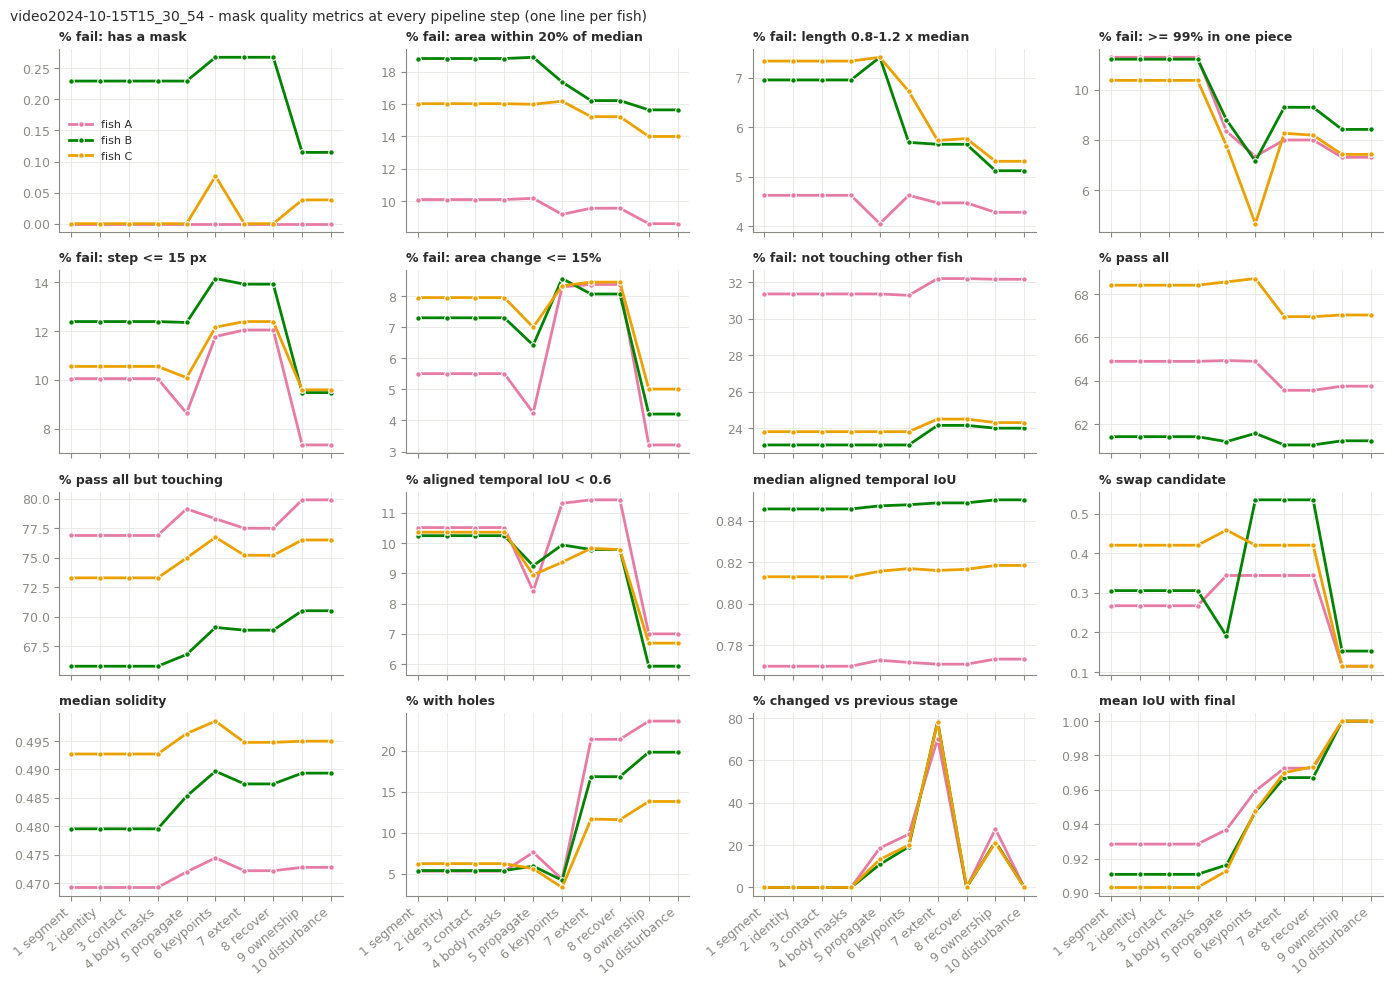

In [7]:
fig = msq.plot_metrics_by_stage(summary, checks, REC)

## 3. What each step changes
Left: % of masks that differ from the previous step's, for fish touching another fish and for isolated fish. Right: how much they change (median IoU with the previous step's mask, changed masks only; 0 = the mask appeared or disappeared).

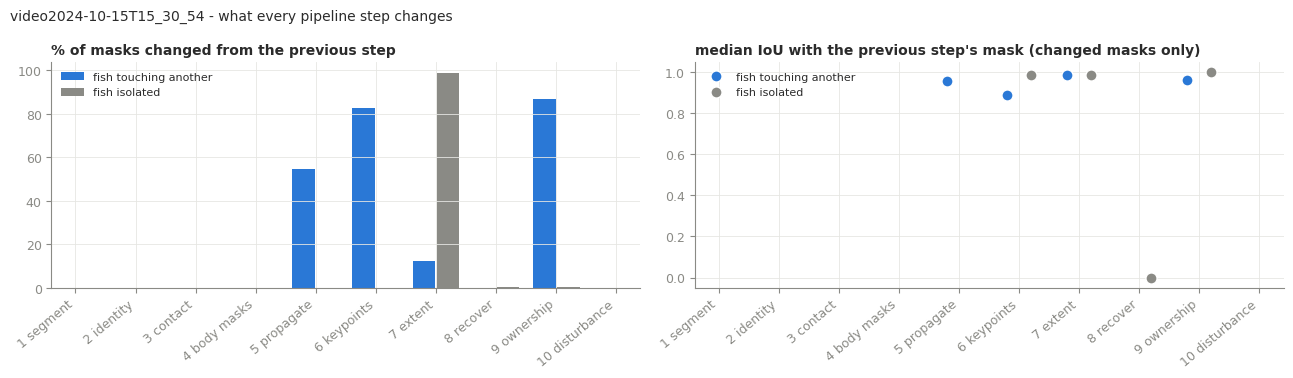

In [8]:
fig = msq.plot_stage_changes(df, REC)

## 4. Where in the video the masks fail
Ticks = frames where a fish fails any rule other than touching; top row = frames with fish touching.

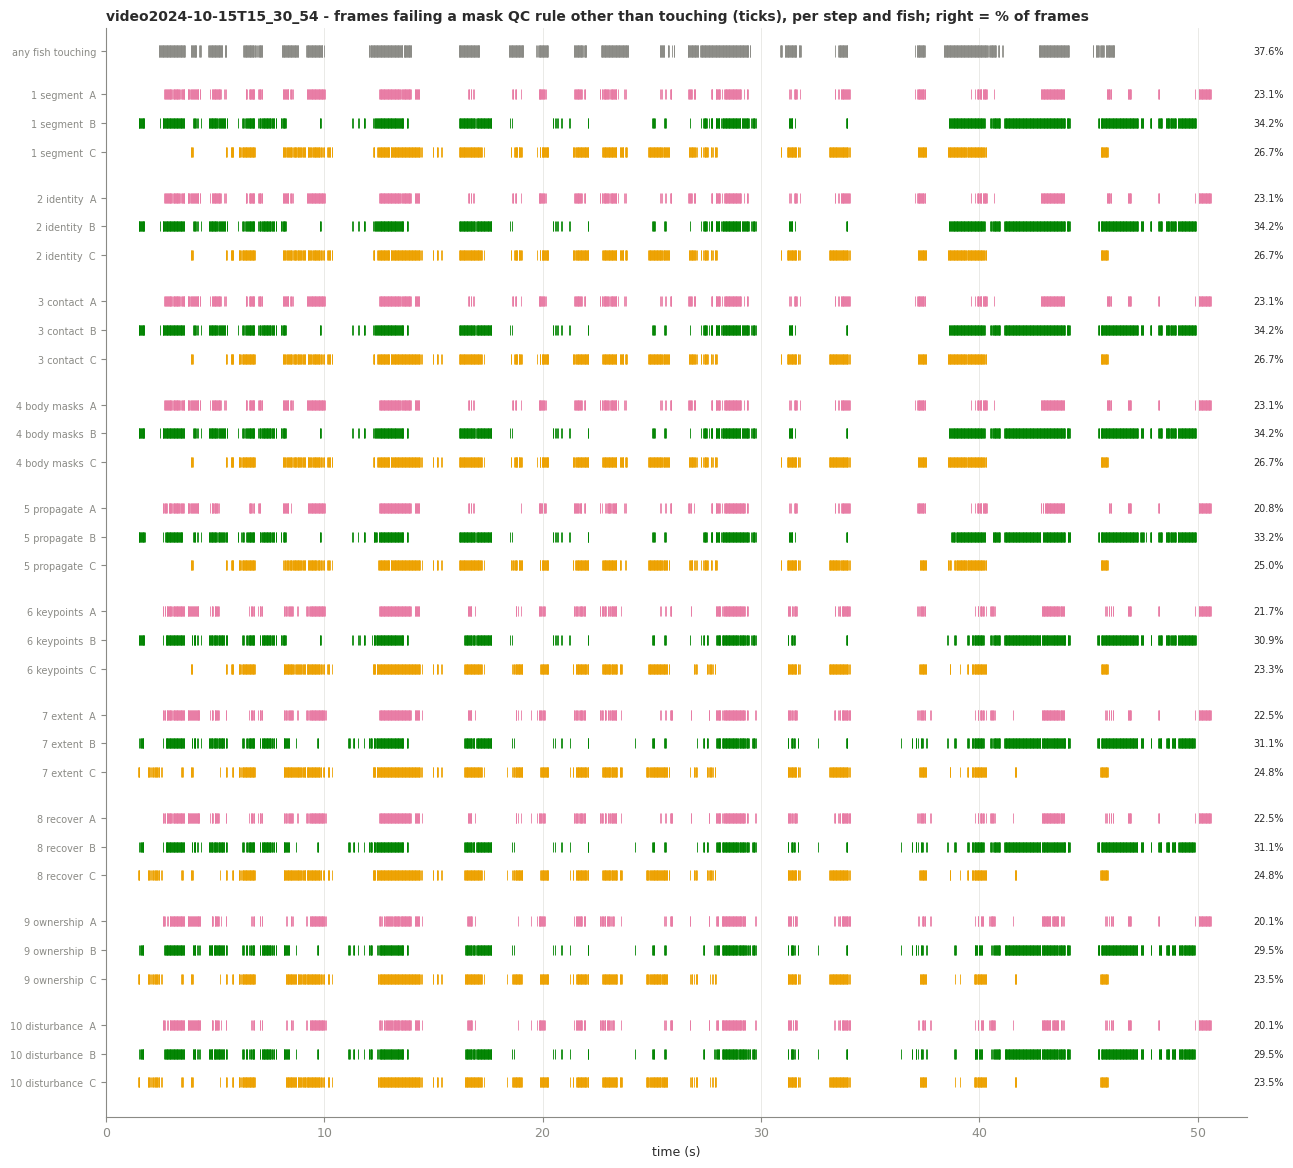

In [9]:
fig = msq.plot_bad_frames_timeline(df, REC, FPS)

## 5. Distributions per step (all fish)

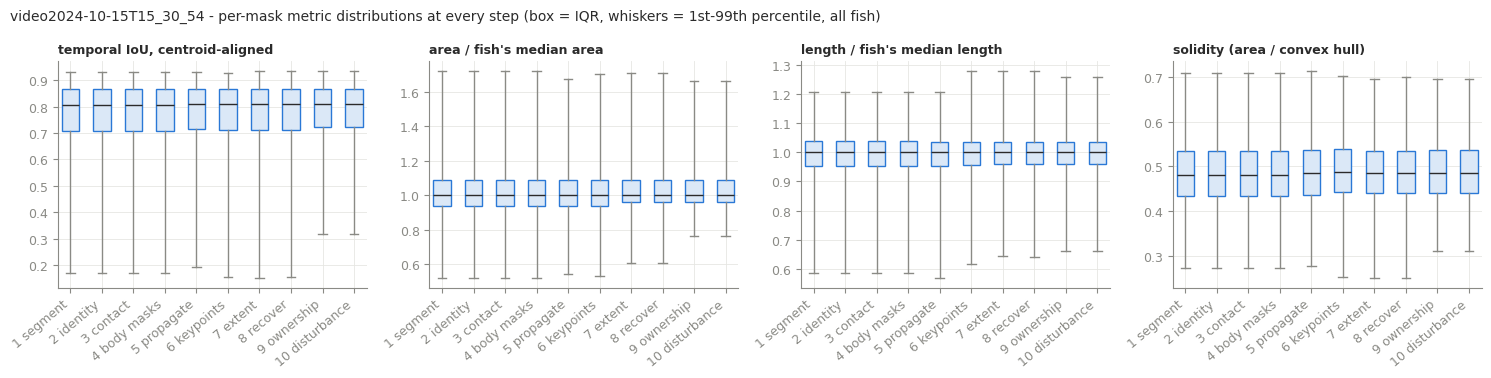

In [10]:
fig = msq.plot_distributions_by_stage(df, REC)

## 6. How much does each step change the masks?
Per step (`mask_metrics.stage_flux`, `stage_change_table`, `net_vs_gross_change`; run times from `io_utils.load_run_summary`):
- **% changed**: fish-frames whose visible mask differs from the previous step's, split into fish touching another fish and isolated fish
- **% of all change**: the step's share of the summed (1 - IoU with the previous step) over the whole pipeline
- **pixels**: added from / removed to the background, and moved between fish, as % of all mask pixels
- **distance to final**: how close the masks already are to the final ones after the step
- **QC fixed / broken**: changed fish-frames going from failing to passing every QC rule except touching, and back

Unchanged visible masks do not make a step droppable: identity, contact and body masks produce inputs later steps use (names, positions in contacts, full-body masks). Only a run without the step shows what dropping it does.

In [11]:
steps, flux = msq.load_or_compute_changes(RUN, df, recompute=RECOMPUTE)
gross, net = mm.net_vs_gross_change(df)
print(f'per fish-frame: summed change over the steps {gross:.3f}, net change first -> final {net:.3f} '
      f'(net / gross {net / gross:.2f}: {100 * (1 - net / gross):.0f}% of the change is later undone)')
steps.set_index('step').round(2)

per fish-frame: summed change over the steps 0.111, net change first -> final 0.086 (net / gross 0.78: 22% of the change is later undone)


,run time (s),% changed,"% changed, touching","% changed, isolated",mean change (1 - IoU),% of all change,% px added,% px removed,% px moved between fish,% QC fixed,% QC broken,% pass all but touching,dist. to final after (1 - IoU),% IoU >= 0.95 with final after,% identical to final after
step,,,,,,,,,,,,,,,
1 segment,5848.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,72.01,0.09,70.36,0.96
2 identity,23.4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,72.01,0.09,70.36,0.96
3 contact,32.8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,72.01,0.09,70.36,0.96
4 body masks,85.1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,72.01,0.09,70.36,0.96
5 propagate,49.4,14.26,54.78,0.00,0.01,13.30,0.00,0.00,0.93,2.09,0.45,73.65,0.08,72.61,1.19
6 keypoints,762.9,21.48,82.47,0.09,0.05,42.57,0.00,0.00,3.14,3.05,2.00,74.72,0.05,79.22,2.36
7 extent,168.7,75.66,12.48,98.90,0.02,16.90,1.03,0.63,0.00,0.68,1.43,73.87,0.03,89.39,76.41
8 recover,7.0,0.13,0.00,0.17,0.00,1.04,0.03,0.03,0.00,0.00,0.00,73.87,0.03,89.52,76.53
9 ownership,130.9,23.47,86.67,0.35,0.03,26.19,0.00,0.00,1.84,2.56,0.87,75.65,0.00,100.00,100.00


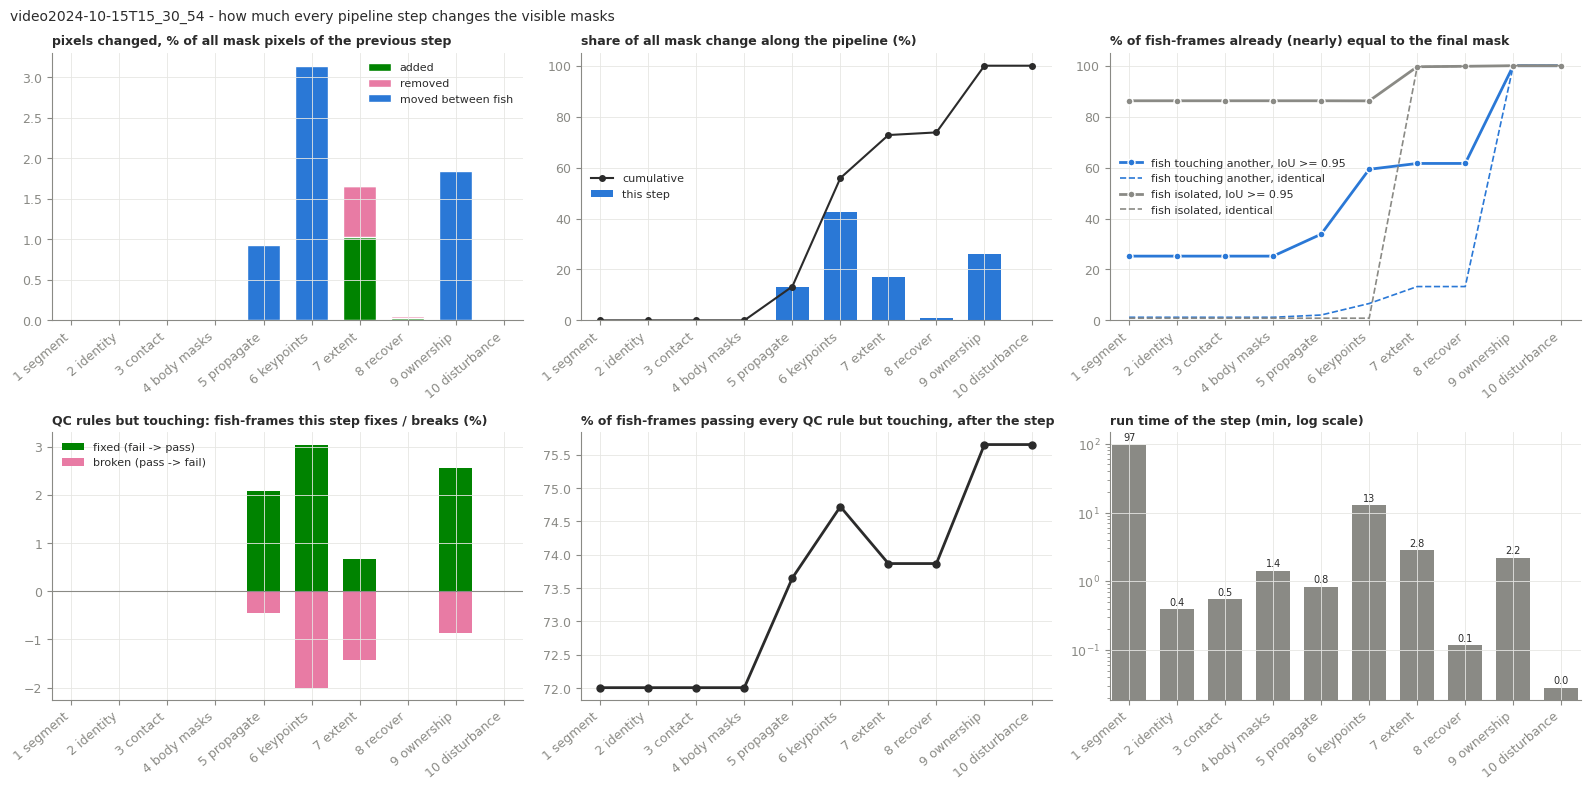

In [12]:
fig = msq.plot_step_changes(steps, df, REC)

## 7. Frames the pipeline redraws most
`mask_metrics.most_changed_frames` ranks frames by how much a fish's mask is redrawn along the pipeline (sum over the steps of 1 - IoU with the previous step's mask), at least `MIN_GAP` frames apart. Each panel: the video crop, then every step's masks (`mask_stage_quality.plot_frame_through_stages`); bold frame = the ranked fish's mask changed at that step. The script writes 50 of these to `results/Kaden_mask_quality/<recording>/` (`--examples 50`).

In [13]:
from io_utils import load_video_frames
N_SHOW, MIN_GAP = 5, 25
ex = mm.most_changed_frames(df, N_SHOW, MIN_GAP)
ex['time_s'] = ex.frame / FPS
vid = msq.video_path(RUN)
imgs = load_video_frames(vid, ex.frame) if vid else {}
ex

,rank,frame,fish,change,iou_first_final,time_s
0,1,1260,C,2.500184,0.000000,25.20
1,2,2008,B,2.015288,0.000000,40.16
2,3,471,C,1.965786,0.000000,9.42
3,4,149,B,1.860262,0.614186,2.98
4,5,1077,C,1.802870,0.514432,21.54


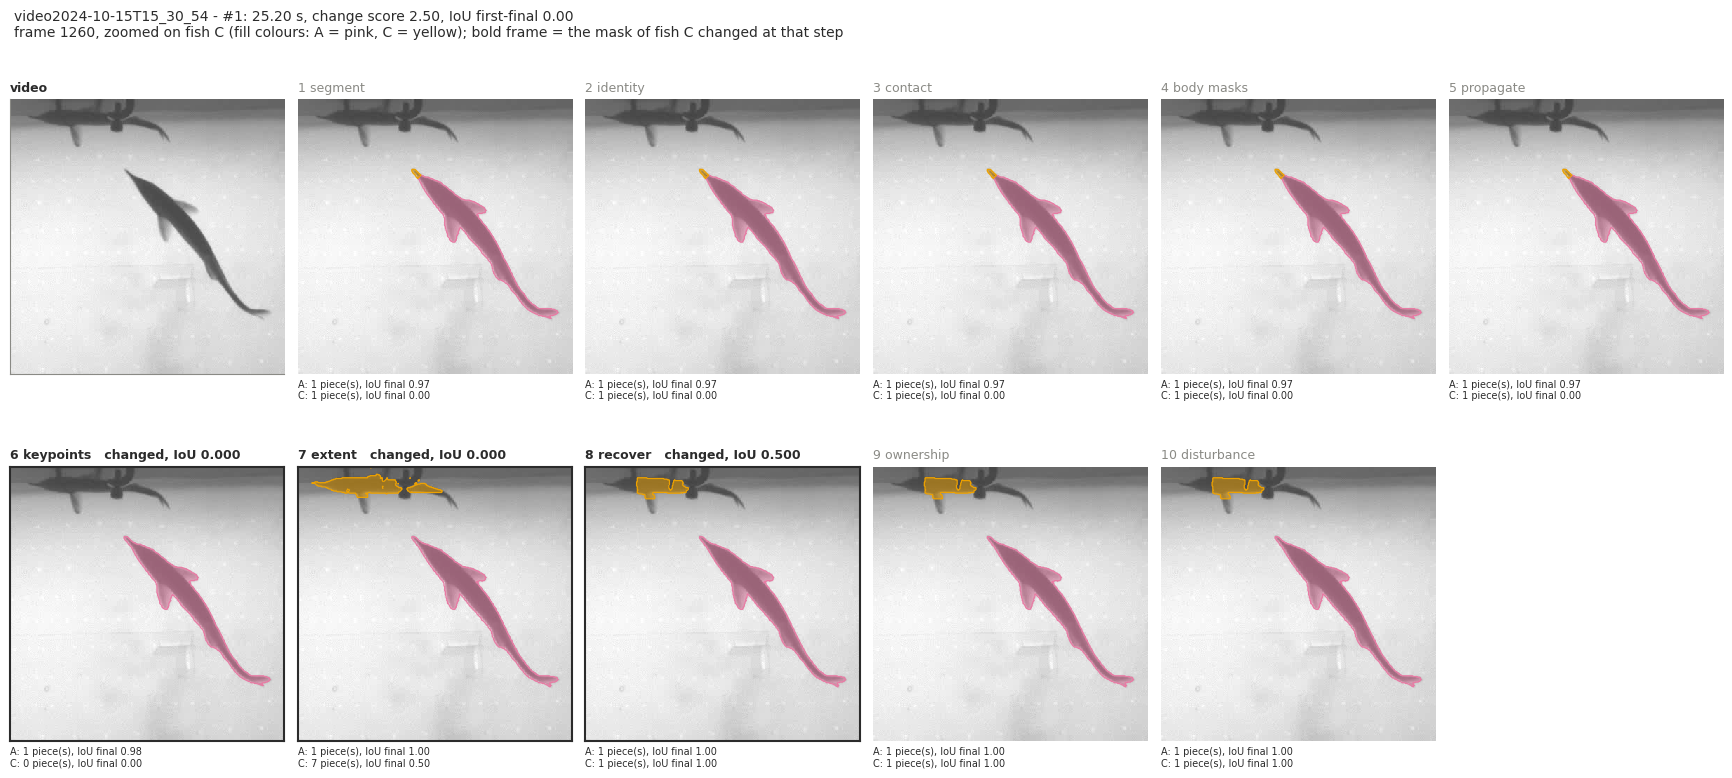

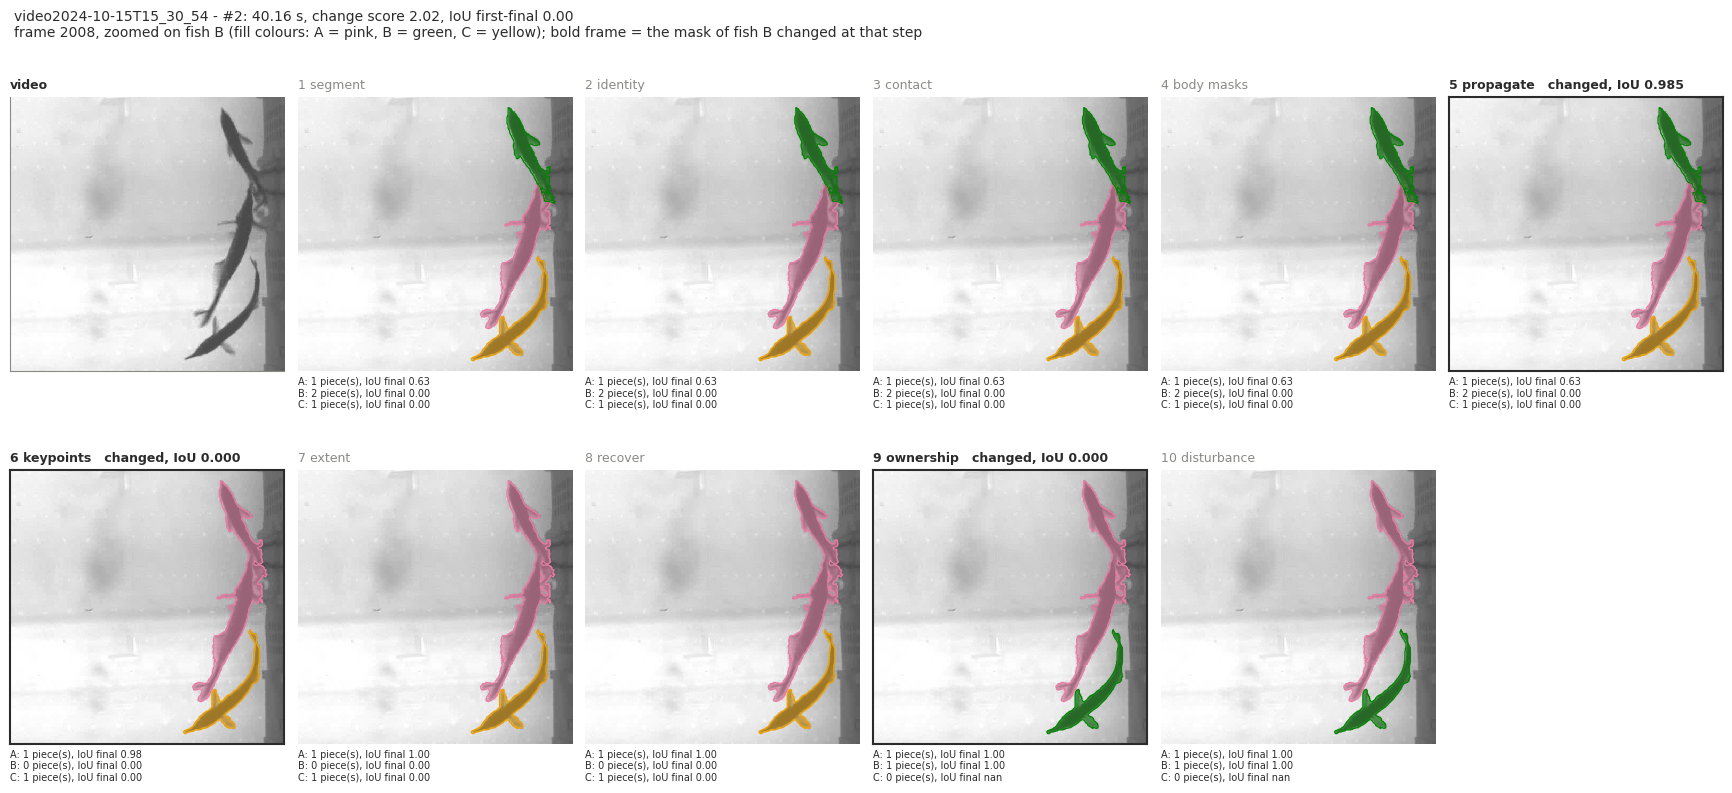

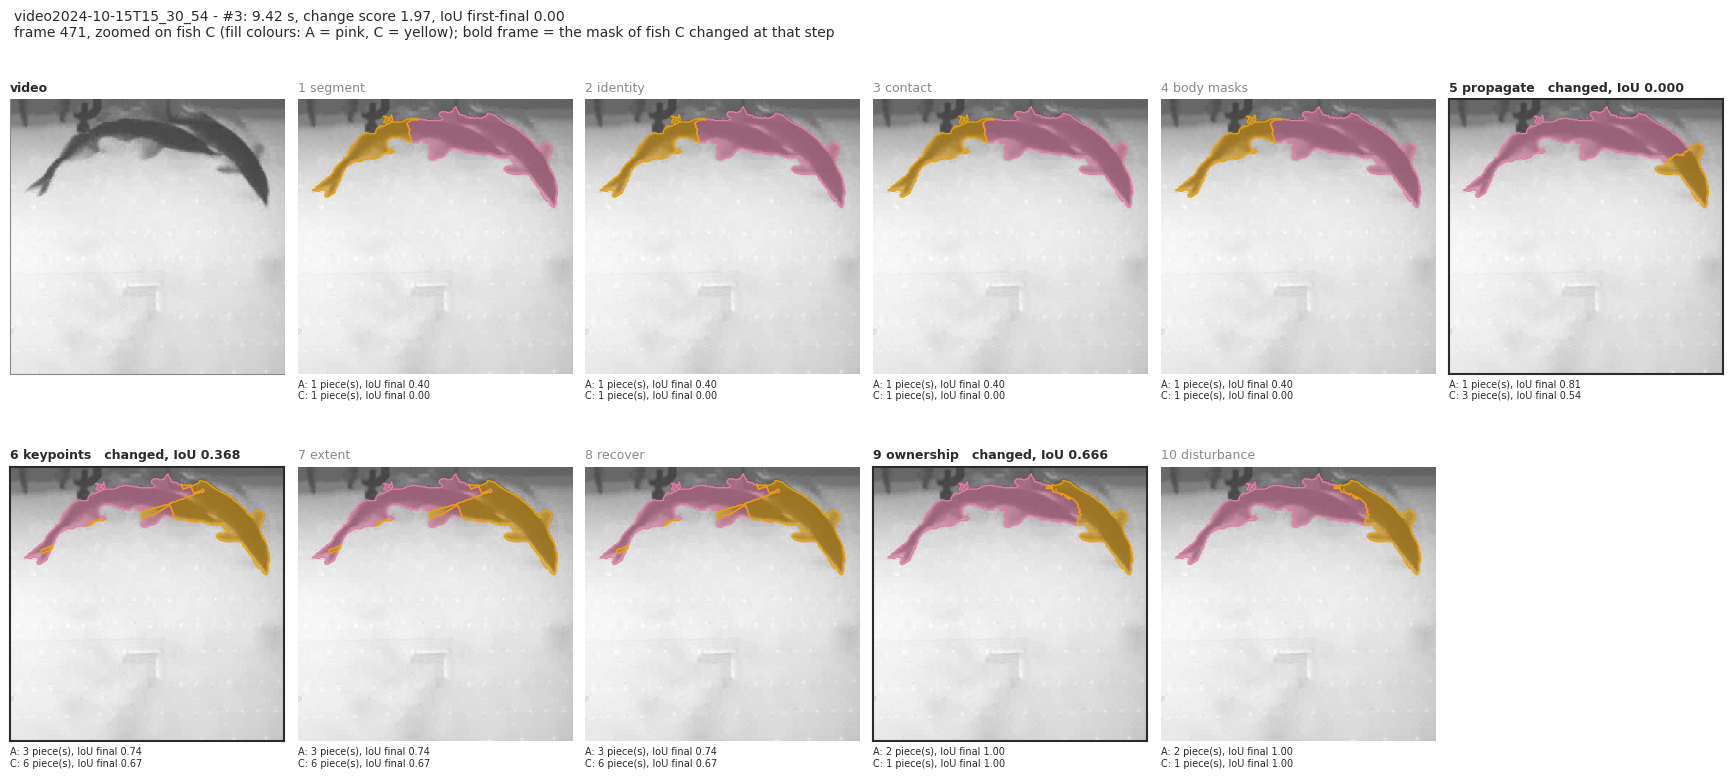

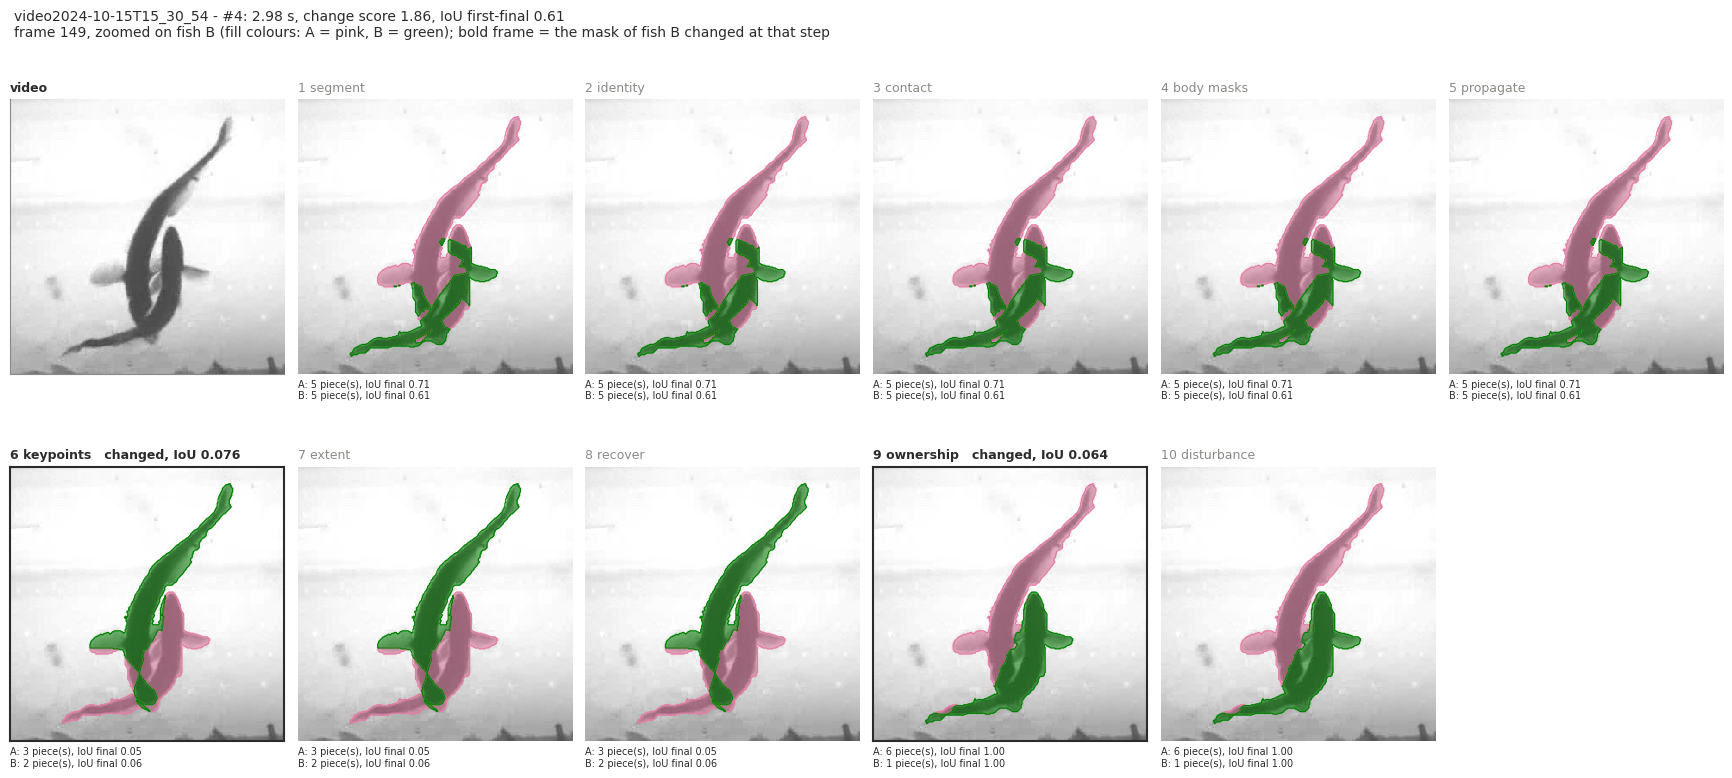

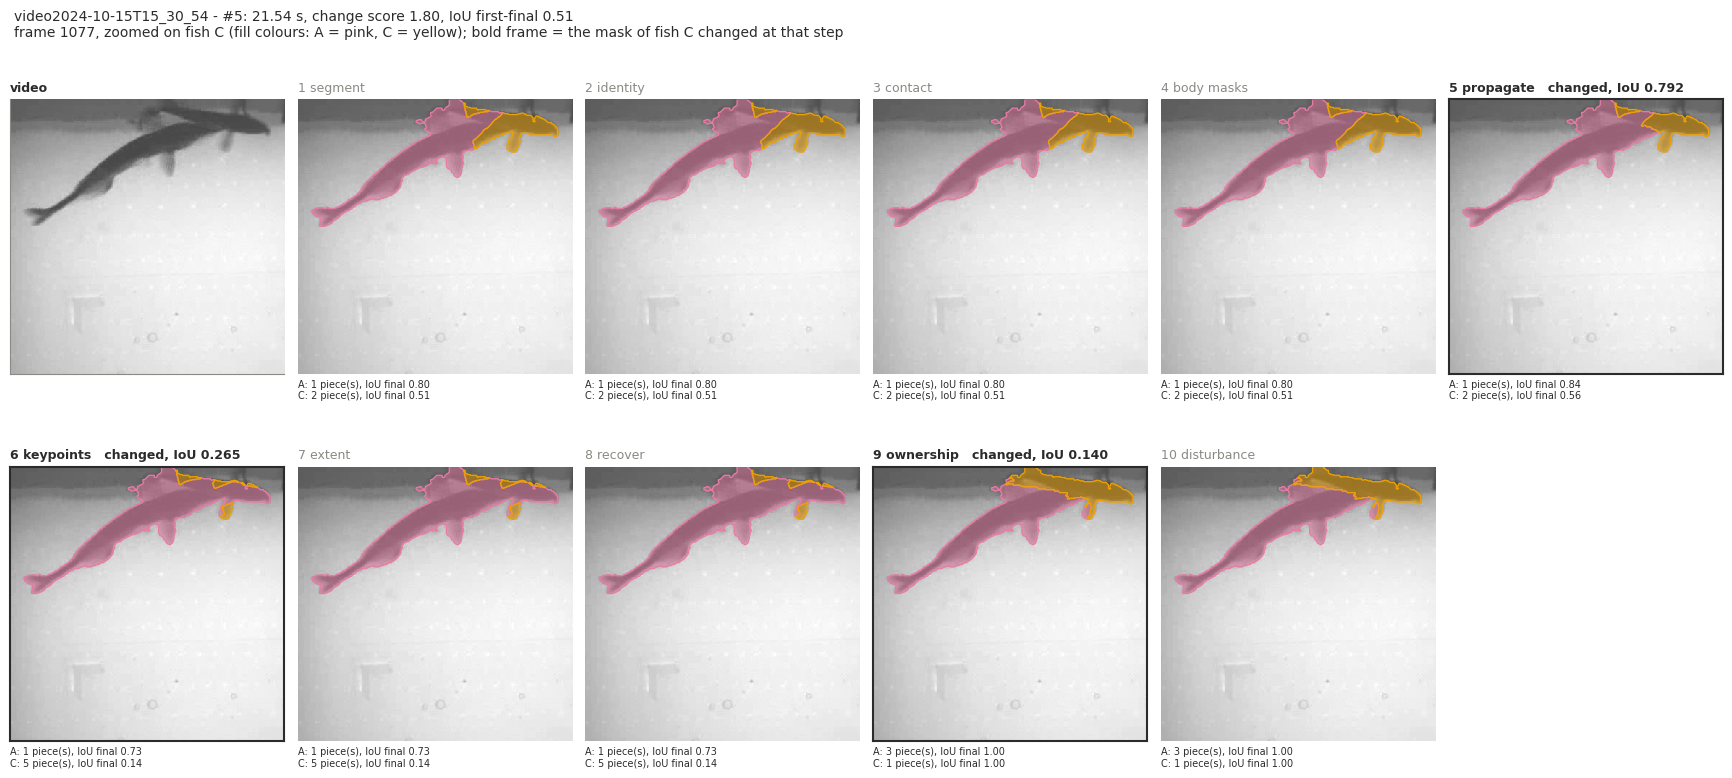

In [14]:
for r in ex.itertuples(index=False):
    fig = msq.plot_frame_through_stages(masks, df, r.frame, r.fish, imgs.get(r.frame),
                                        title=f'{REC} - #{r.rank}: {r.time_s:.2f} s, change score {r.change:.2f}, '
                                              f'IoU first-final {r.iou_first_final:.2f}\n')
    plt.show()